# Simple EC estimation: tau from EC–Q1 correlation
Load one explicitly identified subject, preprocess, fit a tau grid, select tau, and save the selected matrices and diagnostics.
This notebook uses the local pyMOU source. See **README_Q1.md** for conventions and exclusions.


In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from q1_pipeline import estimate_q1, plot_result

ROOT = Path.cwd()
SUBJECT_ID = "100408"
RUN = "REST1_LR"
INPUT_FILE = Path.home() / "hcp_parcellated" / SUBJECT_ID / f"{SUBJECT_ID}_{RUN}_Schaefer100+AAL.npy"
OUTPUT_FILE = ROOT / "results" / f"{SUBJECT_ID}_{RUN}_Q1_pipeline.npz"
OVERWRITE = False
TR = 0.72
TAUS = np.logspace(-0.45, 2, 50)
MAX_ITER = 100
mapping = np.loadtxt(ROOT / "mapping_schaefer100_to62.csv", delimiter=",", dtype=int)
print("Subject:", SUBJECT_ID, "Run:", RUN, "Input:", INPUT_FILE)


Subject: 100408 Run: REST1_LR Input: /home/benedetta/hcp_parcellated/100408/100408_REST1_LR_Schaefer100+AAL.npy


## Fit and select
The score is Pearson correlation over **all ordered off-diagonal entries** of raw pyMOU J and empirical Q1. Q1[i,j] relates earlier i to later j, matching the raw row-source convention. The first contiguous eligible interval is used; its first point and trivial initial-update points are excluded. At least three candidates must remain. Stopping before the iteration cap is an operational convergence criterion, not a proof of optimality.


In [4]:
if OUTPUT_FILE.exists() and not OVERWRITE:
    raise FileExistsError(f"Already saved: {OUTPUT_FILE}. Use the reload cell below.")
raw = np.load(INPUT_FILE, allow_pickle=False)
with threadpool_limits(limits=1):
    result = estimate_q1(raw, TAUS, tr=TR, mapping=mapping, max_iter=MAX_ITER)
result.update(subject_id=np.asarray(SUBJECT_ID), run=np.asarray(RUN),
    input_path=np.asarray(str(INPUT_FILE)),
    input_sha256=np.asarray(hashlib.sha256(INPUT_FILE.read_bytes()).hexdigest()),
    mapping_sha256=np.asarray(hashlib.sha256((ROOT/"mapping_schaefer100_to62.csv").read_bytes()).hexdigest()),
    pymou_sha256=np.asarray(hashlib.sha256((ROOT/"pyMOU-master/pymou/mou_model.py").read_bytes()).hexdigest()),
    settings_json=np.asarray(json.dumps(dict(tr=TR, bandpass=[0.01,0.1], n_regions=100,
        lag=1, eta_C=0.005, max_iter=MAX_ITER, selection="max corr(J_raw,Q1), off-diagonal"))))
OUTPUT_FILE.parent.mkdir(exist_ok=True)
np.savez_compressed(OUTPUT_FILE, **result)
if int(result["best_index"]) < 0:
    raise RuntimeError("Insufficient eligible points; diagnostics saved. No EC selected.")
print("Tau:", float(result["tau_opt"]), "samples;", float(result["tau_opt"])*TR, "seconds")
print("Boundary maximum:", bool(result["boundary_maximum"]), "(inspect the curve if True)")
print("Saved:", OUTPUT_FILE)


Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Max

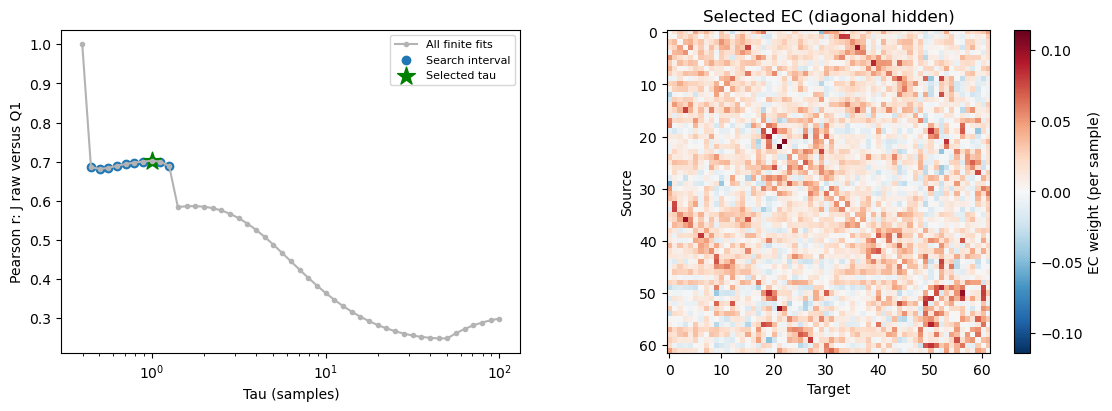

In [5]:
fig = plot_result(result)
plt.show()
# Optional figure export:
# fig.savefig(OUTPUT_FILE.with_suffix(".jpg"), dpi=300, bbox_inches="tight")


## EC similarity across tau
Pearson correlations between all ordered off-diagonal EC entries, within the retained search interval. High correlation describes similarity of patterns, not equality of weight magnitudes. The full color scale is fixed at −1 to 1.

EC across tau: mean r = 0.9960; minimum r = 0.9829


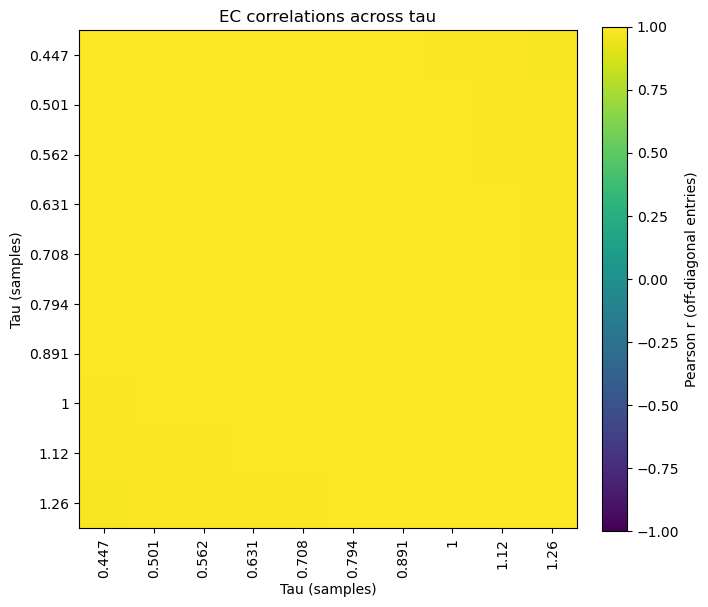

In [7]:
# Compare the valid EC estimates across tau, excluding every diagonal.
indices = np.flatnonzero(result["search_mask"])
if len(indices) < 3:
    raise RuntimeError("Insufficient eligible EC estimates for comparison.")
offdiag = ~np.eye(result["J_grid"].shape[1], dtype=bool)
vectors = result["J_grid"][indices][:, offdiag]
ec_correlations = np.corrcoef(vectors)
selected_taus = result["taus"][indices]
pairwise = ec_correlations[np.triu_indices(len(indices), k=1)]
print(f"EC across tau: mean r = {pairwise.mean():.4f}; minimum r = {pairwise.min():.4f}")
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(ec_correlations, cmap="viridis", vmin=-1, vmax=1)
labels = [f"{tau:.3g}" for tau in selected_taus]
ax.set_xticks(range(len(indices)), labels, rotation=90)
ax.set_yticks(range(len(indices)), labels)
ax.set(xlabel="Tau (samples)", ylabel="Tau (samples)", title="EC correlations across tau")
fig.colorbar(im, ax=ax, label="Pearson r (off-diagonal entries)")
plt.show()
np.savez_compressed(OUTPUT_FILE.with_name(OUTPUT_FILE.stem + "_EC_correlations.npz"),
    taus=selected_taus, correlations=ec_correlations,
    subject_id=result["subject_id"], run=result["run"])
# Optional figure export:
# fig.savefig(OUTPUT_FILE.with_name(OUTPUT_FILE.stem + "_EC_correlations.jpg"), dpi=300, bbox_inches="tight")


## Reload without fitting again
Run the setup cell, then this cell.

Subject: 100408 Run: REST1_LR Tau: 1.0


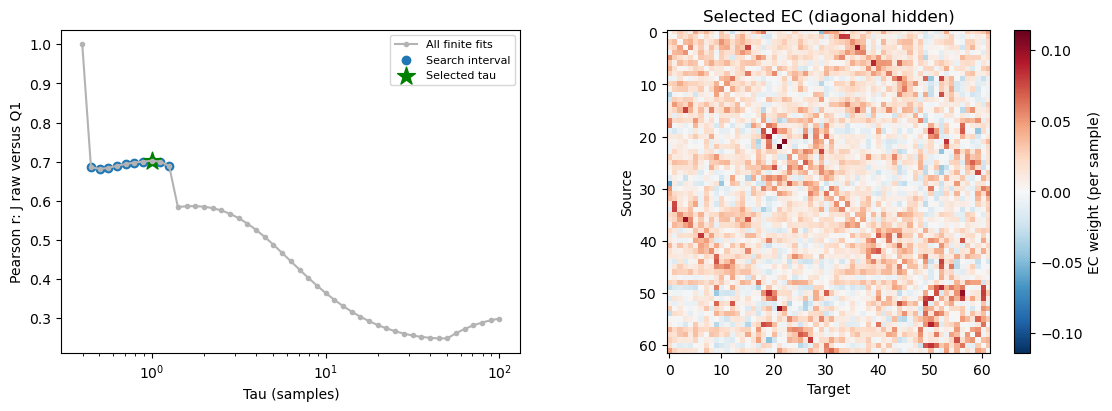

In [9]:
with np.load(OUTPUT_FILE, allow_pickle=False) as saved:
    result = {key: saved[key] for key in saved.files}
assert str(result["subject_id"]) == SUBJECT_ID and str(result["run"]) == RUN
print("Subject:", result["subject_id"], "Run:", result["run"], "Tau:", result["tau_opt"])
fig = plot_result(result)
plt.show()
